# 3. Distribution analysis

Explore variable shape and concentration, identify potential outliers, and compare distributions across meaningful groups.

In [28]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("../data/final_destination.csv")


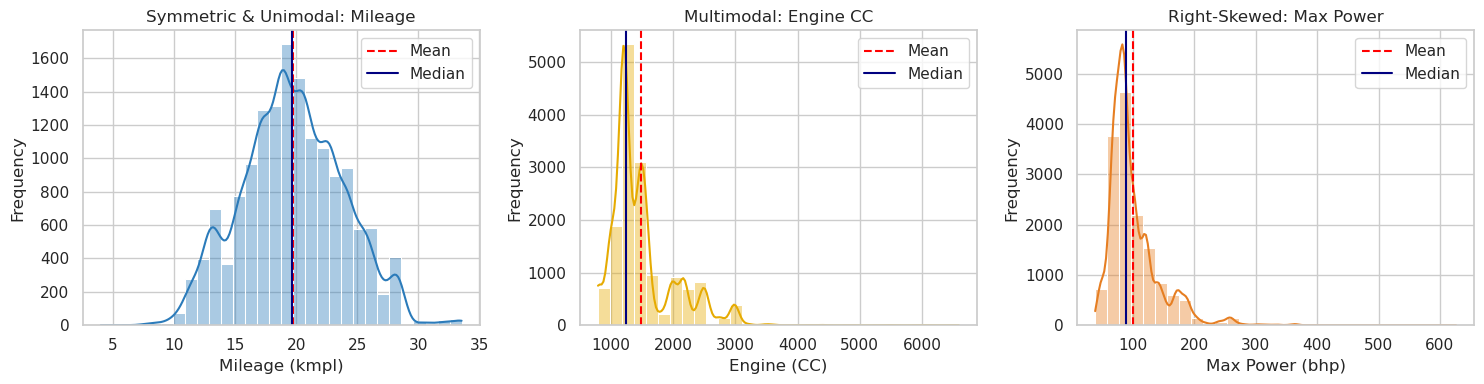

In [29]:
# ==============================================================================
    # 1. Distribution Shape: Histograms and KDE (Symmetric, Multimodal, Right-Skewed)
    # ==============================================================================
plt.figure(figsize=(15, 4))

    # Symmetric & Unimodal -> Blue (Slide 28)
plt.subplot(1, 3, 1)
sns.histplot(df["mileage"], kde=True, bins=30, color="#2b7bba", alpha=0.4)
plt.axvline(df["mileage"].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(df["mileage"].median(), color="navy", linestyle="-", label="Median")
plt.title("Symmetric & Unimodal: Mileage")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Frequency")
plt.legend()

    # Multimodal -> Gold (Slide 28)
plt.subplot(1, 3, 2)
sns.histplot(df["engine"], kde=True, bins=30, color="#e6ab02", alpha=0.4)
plt.axvline(df["engine"].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(df["engine"].median(), color="navy", linestyle="-", label="Median")
plt.title("Multimodal: Engine CC")
plt.xlabel("Engine (CC)")
plt.ylabel("Frequency")
plt.legend()

    # Right-Skewed -> Orange (Slide 28)
plt.subplot(1, 3, 3)
sns.histplot(df["max_power"], kde=True, bins=30, color="#e67e22", alpha=0.4)
plt.axvline(df["max_power"].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(df["max_power"].median(), color="navy", linestyle="-", label="Median")
plt.title("Right-Skewed: Max Power")
plt.xlabel("Max Power (bhp)")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()



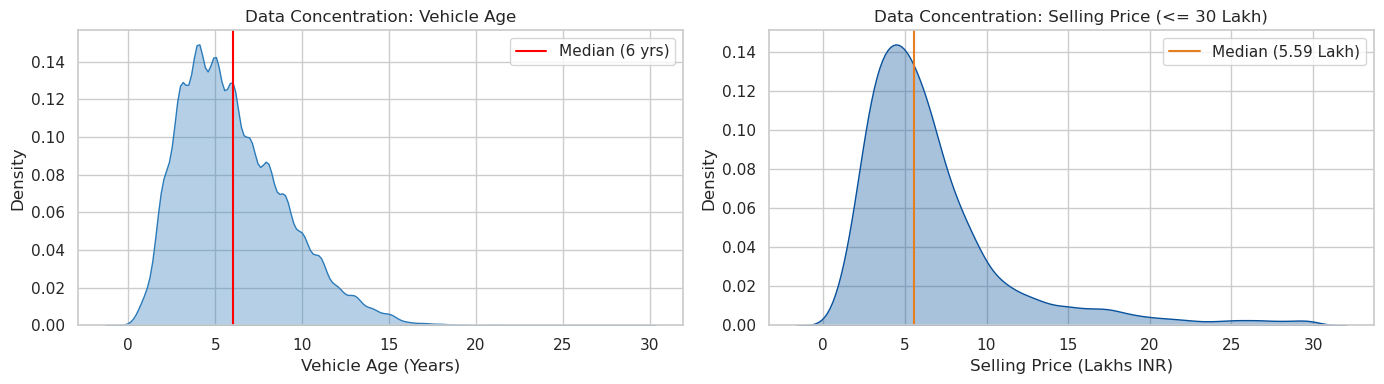

In [30]:
 # 2. Data Concentration: KDE Plots showing where observations are concentrated
    # ==============================================================================
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.kdeplot(df["vehicle_age"], fill=True, color="#2b7bba", alpha=0.35)
plt.axvline(df["vehicle_age"].median(), color="red", linestyle="-", label="Median (6 yrs)")
plt.title("Data Concentration: Vehicle Age")
plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Density")
plt.legend()

plt.subplot(1, 2, 2)
sns.kdeplot(df[df["selling_price"] <= 3000000]["selling_price"] / 1e5, fill=True, color="#08519c", alpha=0.35)
plt.axvline(df["selling_price"].median() / 1e5, color="#e67e22", linestyle="-", label="Median (5.59 Lakh)")
plt.title("Data Concentration: Selling Price (<= 30 Lakh)")
plt.xlabel("Selling Price (Lakhs INR)")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()



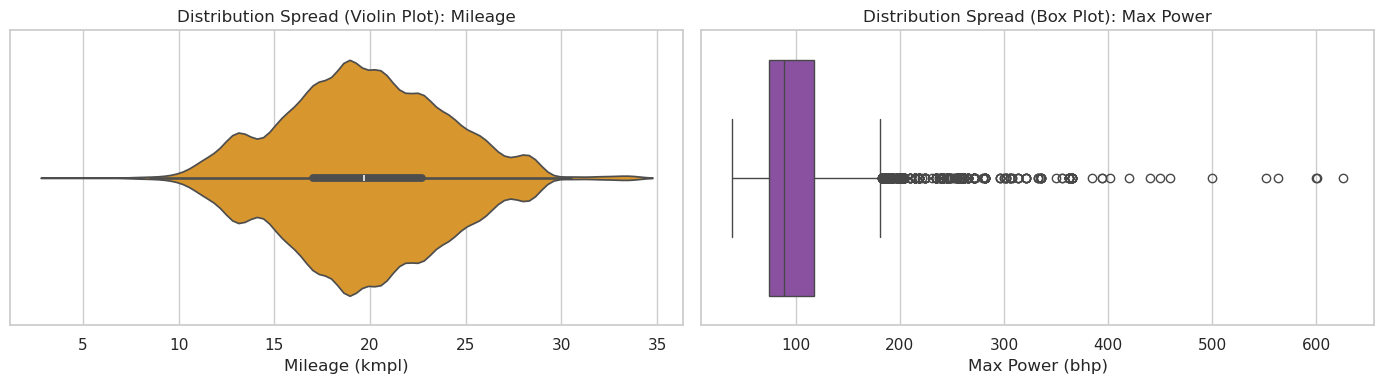

In [31]:
  # 3. Distribution Spread: Violin Plot & Box Plot (Slides 35-37 & 45-46)
    # ==============================================================================
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.violinplot(x=df["mileage"], color="#f39c12", inner="box")
plt.title("Distribution Spread (Violin Plot): Mileage")
plt.xlabel("Mileage (kmpl)")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["max_power"], color="#8e44ad")
plt.title("Distribution Spread (Box Plot): Max Power")
plt.xlabel("Max Power (bhp)")

plt.tight_layout()
plt.show()


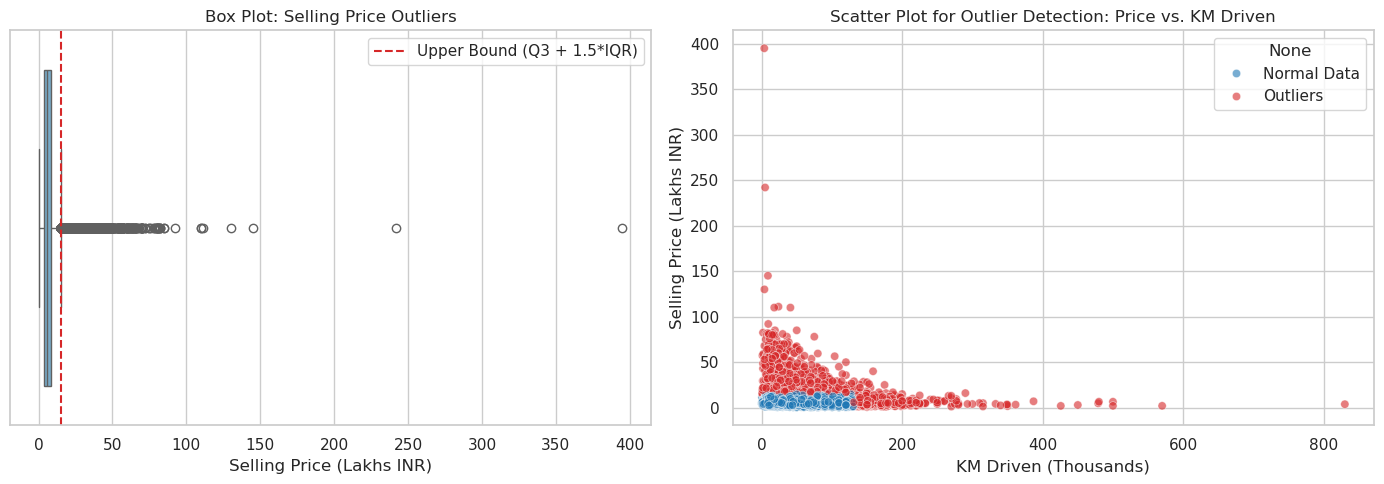

In [32]:
 # 4. Outlier Detection: Box Plot & Scatter Plot using IQR Rule (Slide 34 & Note.txt)
    # ==============================================================================
q1_p, q3_p = df["selling_price"].quantile([0.25, 0.75])
upper_p = q3_p + 1.5 * (q3_p - q1_p)

q1_k, q3_k = df["km_driven"].quantile([0.25, 0.75])
upper_k = q3_k + 1.5 * (q3_k - q1_k)

outliers = ((df["selling_price"] > upper_p) | (df["km_driven"] > upper_k)).map(
    {False: "Normal Data", True: "Outliers"}
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df["selling_price"] / 1e5, color="#6baed6")
plt.axvline(upper_p / 1e5, color="#d62728", linestyle="--", label="Upper Bound (Q3 + 1.5*IQR)")
plt.title("Box Plot: Selling Price Outliers")
plt.xlabel("Selling Price (Lakhs INR)")
plt.legend()

plt.subplot(1, 2, 2)
sns.scatterplot(
        x=df["km_driven"] / 1e3,
        y=df["selling_price"] / 1e5,
        hue=outliers,
        palette={"Normal Data": "#1f77b4", "Outliers": "#d62728"},
        alpha=0.6
    )
plt.title("Scatter Plot for Outlier Detection: Price vs. KM Driven")
plt.xlabel("KM Driven (Thousands)")
plt.ylabel("Selling Price (Lakhs INR)")

plt.tight_layout()
plt.show()


ValueError: Could not interpret value `brand_tier` for `x`. An entry with this name does not appear in `data`.

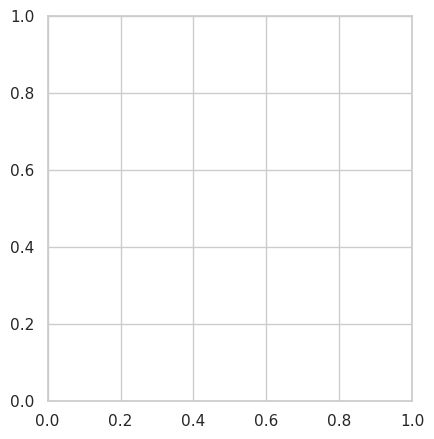

In [33]:
    # 5. Distribution Comparison Across Categories (Slides 64, 66 & 68 Color Harmony)
    # ==============================================================================
plt.figure(figsize=(16, 5))
    
    # Monochromatic Blue (Slide 64)
plt.subplot(1, 3, 1)
sns.boxplot(
        data=df,
        x="brand_tier",
        y="selling_price",
        order=["Economy", "Mid", "Luxury"],
        hue="brand_tier",
        palette=["#c6dbef", "#6baed6", "#08519c"],
        legend=False
    )
plt.yscale("log")
plt.title("Grouped Box Plot: Price by Brand Tier")
plt.xlabel("Brand Tier")
plt.ylabel("Selling Price (Log Scale)")

    # Complementary Blue & Orange (Slide 66)
plt.subplot(1, 3, 2)
sns.violinplot(
        data=df,
        x="transmission_type",
        y="selling_price",
        hue="transmission_type",
        palette=["#1f77b4", "#ff7f0e"],
        inner="box",
        legend=False
    )
plt.yscale("log")
plt.title("Violin Plot: Price by Transmission")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price (Log Scale)")



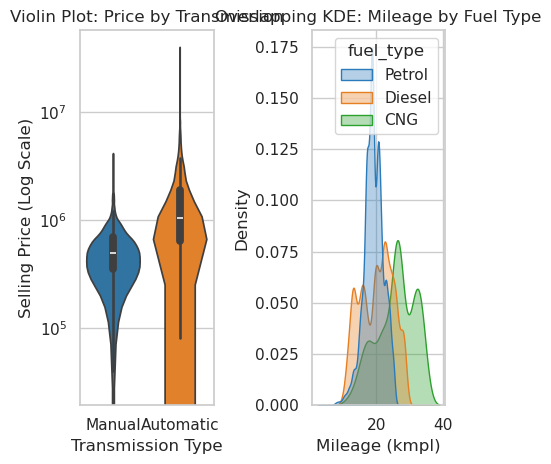

In [ ]:
  # Complementary Blue & Orange (Slide 66)
plt.subplot(1, 3, 2)
sns.violinplot(
        data=df,
        x="transmission_type",
        y="selling_price",
        hue="transmission_type",
        palette=["#1f77b4", "#ff7f0e"],
        inner="box",
        legend=False
    )
plt.yscale("log")
plt.title("Violin Plot: Price by Transmission")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price (Log Scale)")

    # Triadic Colors (Slide 68)
plt.subplot(1, 3, 3)
top_fuels = df[df["fuel_type"].isin(["Petrol", "Diesel", "CNG"])]
sns.kdeplot(
        data=top_fuels,
        x="mileage",
        hue="fuel_type",
        palette=["#2b7bba", "#e67e22", "#2ca02c"],
        fill=True,
        common_norm=False,
        alpha=0.35
    )
plt.title("Overlapping KDE: Mileage by Fuel Type")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

